# 4.1 How slabs load the beams

One-way slabs load the two long beams only. Two-way slabs load all four. Two methods are shown for the typical floor panels, and checked against total equilibrium.

In [1]:
import sys; sys.path.insert(0, '..')
from ec2.setup import *

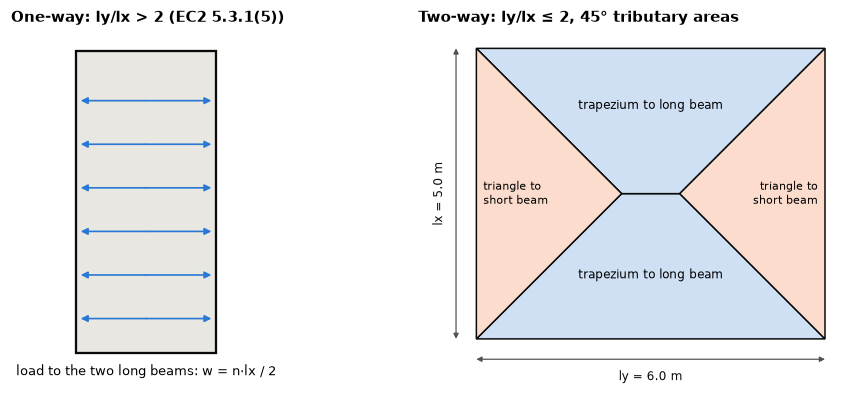

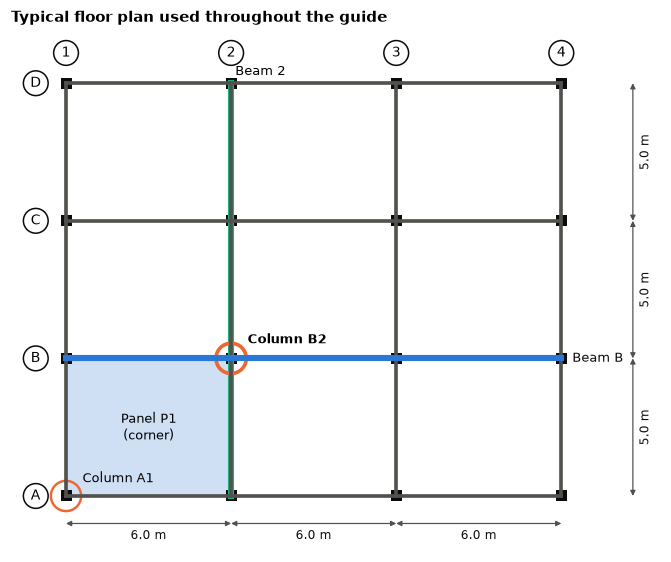

In [2]:
P.sketch_slab_load(BRIEF["ly_bay"], BRIEF["lx_bay"])
P.sketch_plan()

## Method 1: shear coefficients (used in the design)

BS 8110-1 Table 3.15: $v_{sx}=\beta_{vx}nl_x$ on the long edges and $v_{sy}=\beta_{vy}nl_x$ on the short edges, acting on the **middle three-quarters** of the beam. Each beam adds the shear from the panel on each side.

In [3]:
c, w = PJ.line_loads(); g, q = PJ.area_loads(); lx = BRIEF["ly_bay"]
s = Sheet("Slab loads on Beam B", element="Beam B, end span")
s.let("g_k", g, "kN/m²", "Permanent area load (Notebook 2.1)"); s.let("q_k", q, "kN/m²", "Variable area load"); s.let("l_x", lx, "m", "Short span")
s.let("beta_1", c["B"][0][0], "", "Corner panel, continuous long edge (interpolated at ly/lx = 1.2)", "BS 8110-1 Table 3.15")
s.let("beta_2", c["B"][0][1], "", "Panel on the other side: one short edge discontinuous", "BS 8110-1 Table 3.15")
s.calc("g_B", "(beta_1 + beta_2)*g_k*l_x", "kN/m", "", "Permanent, middle ¾ of the span"); s.calc("q_B", "(beta_1 + beta_2)*q_k*l_x", "kN/m", "", "Variable, middle ¾ of the span")
s.let("b_w", BRIEF["beam"][0], "mm"); s.let("h", BRIEF["beam"][1], "mm"); s.let("h_f", BRIEF["h_slab"], "mm")
s.calc("g_dw", "25*b_w*(h - h_f)/1e6", "kN/m", "EN 1991-1-1 Table A.1", "Downstand self-weight, whole span"); s.show()
rows = []
for ln, t in w.items():
    for i, (gg, qq) in enumerate(t):
        rows.append([f"Beam {ln}", i + 1, f"{c[ln][i][0]:.2f} + {c[ln][i][1]:.2f}" if c[ln][i][1] else f"{c[ln][i][0]:.2f}", round(gg, 2), round(qq, 2)])
table(rows, ["Beam", "Span", "β", "g (kN/m)", "q (kN/m)"], "Characteristic slab loads, middle ¾ of each span (edge beams also carry the façade line load)")

## Slab loads on Beam B

*Project:* EC2 design guide &nbsp;|&nbsp; *Element:* Beam B, end span

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Permanent area load (Notebook 2.1): $g_{k}$ | $g_{k} = 5.875$ kN/m²<br><small>(= 5875 Pa)</small> |
|  | Variable area load: $q_{k}$ | $q_{k} = 3.8$ kN/m²<br><small>(= 3800 Pa)</small> |
|  | Short span: $l_{x}$ | $l_{x} = 5$ m |
| BS 8110-1 Table 3.15 | Corner panel, continuous long edge (interpolated at ly/lx = 1.2): $\beta_{1}$ | $\beta_{1} = 0.47$  |
| BS 8110-1 Table 3.15 | Panel on the other side: one short edge discontinuous: $\beta_{2}$ | $\beta_{2} = 0.42$  |
|  | Permanent, middle ¾ of the span<br>$g_{B} = \left(\beta_{1} + \beta_{2}\right)\,g_{k}\,l_{x}$<br>$\quad = \left(0.47 + 0.42\right)\times 5.875\times 5$ | $\mathbf{g_{B} = 26.14}$ kN/m |
|  | Variable, middle ¾ of the span<br>$q_{B} = \left(\beta_{1} + \beta_{2}\right)\,q_{k}\,l_{x}$<br>$\quad = \left(0.47 + 0.42\right)\times 3.8\times 5$ | $\mathbf{q_{B} = 16.91}$ kN/m |
|  | $b_{w}$ | $b_{w} = 300$ mm |
|  | $h$ | $h = 500$ mm |
|  | $h_{f}$ | $h_{f} = 175$ mm |
| EN 1991-1-1 Table A.1 | Downstand self-weight, whole span<br>$g_{dw} = \dfrac{25\,b_{w}\,\left(h - h_{f}\right)}{10^{6}}$<br>$\quad = \dfrac{25\times 300\times \left(500 - 175\right)}{10^{6}}$ | $\mathbf{g_{dw} = 2.438}$ kN/m |


**Characteristic slab loads, middle ¾ of each span (edge beams also carry the façade line load)**

| Beam | Span | β | g (kN/m) | q (kN/m) |
|:--|:-:|:-:|:-:|:-:|
| Beam B | 1 | 0.47 + 0.42 | 26.14 | 16.91 |
| Beam B | 2 | 0.44 + 0.39 | 24.38 | 15.77 |
| Beam B | 3 | 0.47 + 0.42 | 26.14 | 16.91 |
| Beam A | 1 | 0.31 | 9.11 | 5.89 |
| Beam A | 2 | 0.29 | 8.52 | 5.51 |
| Beam A | 3 | 0.31 | 9.11 | 5.89 |
| Beam 2 | 1 | 0.40 + 0.36 | 22.32 | 14.44 |
| Beam 2 | 2 | 0.36 + 0.33 | 20.27 | 13.11 |
| Beam 2 | 3 | 0.40 + 0.36 | 22.32 | 14.44 |
| Beam 1 | 1 | 0.26 | 7.64 | 4.94 |
| Beam 1 | 2 | 0.24 | 7.05 | 4.56 |
| Beam 1 | 3 | 0.26 | 7.64 | 4.94 |


## Method 2: 45° tributary areas

The panel corners are bisected at 45°. The long beams get trapezia and the short beams triangles.

## 45° tributary areas

*Project:* EC2 design guide &nbsp;|&nbsp; *Element:* One panel

| Reference | Calculation | Output |
|:--|:--|:--|
|  | $l_{x}$ | $l_{x} = 5$ m |
|  | $l_{y}$ | $l_{y} = 6$ m |
| Geometry | To each long beam<br>$A_{trap} = \dfrac{\dfrac{l_{y} + l_{y} - l_{x}}{2}\,l_{x}}{2}$<br>$\quad = \dfrac{\dfrac{6 + 6 - 5}{2}\times 5}{2}$ | $\mathbf{A_{trap} = 8.75}$ m² |
| Geometry | To each short beam<br>$A_{tri} = \dfrac{\dfrac{l_{x}}{2}\,l_{x}}{2}$<br>$\quad = \dfrac{\dfrac{5}{2}\times 5}{2}$ | $\mathbf{A_{tri} = 6.25}$ m² |
|  | $A_{sum} = 2\,A_{trap} + 2\,A_{tri}$<br>$\quad = 2\times 8.75 + 2\times 6.25$ | $\mathbf{A_{sum} = 30}$ m² |
|  | $A_{panel} = l_{x}\,l_{y}$<br>$\quad = 5\times 6$ | $\mathbf{A_{panel} = 30}$ m² |
|  | **Check:** areas add up to the panel | ✅ **PASS** |


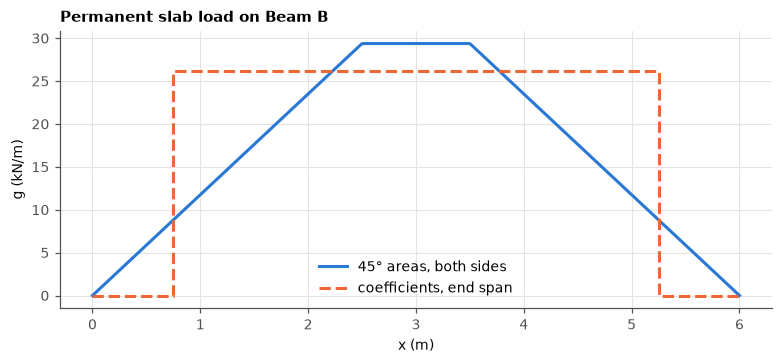

Free bending moment in the end span (permanent slab load): **110.3 kN·m** by coefficients, **101.6 kN·m** by 45° areas ($wL^2/24\,[3-4(a/L)^2]$, a = lx/2).

In [4]:
s = Sheet("45° tributary areas", element="One panel")
s.let("l_x", BRIEF["ly_bay"], "m"); s.let("l_y", BRIEF["lx_bay"], "m")
s.calc("A_trap", "(l_y + (l_y - l_x))/2*l_x/2", "m²", "Geometry", "To each long beam"); s.calc("A_tri", "l_x/2*l_x/2", "m²", "Geometry", "To each short beam")
s.calc("A_sum", "2*A_trap + 2*A_tri", "m²"); s.calc("A_panel", "l_x*l_y", "m²"); s.verdict(abs(s["A_sum"] - s["A_panel"]) < 1e-9, "areas add up to the panel"); s.show()
Lb = BRIEF["lx_bay"]; x = np.linspace(0, Lb, 400); f, ax = plt.subplots(figsize=(7, 3.2))
trap = 2 * np.minimum.reduce([x, Lb - x, np.full_like(x, lx / 2)]) * g
ax.plot(x, trap, color=P.BLUE, lw=2, label="45° areas, both sides"); ax.plot([0, Lb / 8, Lb / 8, 7 * Lb / 8, 7 * Lb / 8, Lb], [0, 0, w["B"][0][0], w["B"][0][0], 0, 0], color=P.ORANGE, lw=2, ls="--", label="coefficients, end span")
ax.set_xlabel("x (m)"); ax.set_ylabel("g (kN/m)"); ax.set_title("Permanent slab load on Beam B"); ax.legend(); plt.show()
m1 = DeterminateBeam(Lb, [UDL(w["B"][0][0], Lb / 8, 7 * Lb / 8)], supports=(0, Lb)).M.max()
m2 = trap.max() * Lb**2 / 24 * (3 - 4 * (lx / 2 / Lb) ** 2)
display(Markdown(f"Free bending moment in the end span (permanent slab load): **{m1:.1f} kN·m** by coefficients, **{m2:.1f} kN·m** by 45° areas ($wL^2/24\\,[3-4(a/L)^2]$, a = lx/2)."))

The coefficient method gives the first interior beam more load because the slab is continuous over it. It is therefore used for design.

## Equilibrium check on the whole floor

In [5]:
s = Sheet("Floor equilibrium", element="Whole floor, slab load only")
tot = sum((a + b) * .75 * (BRIEF["lx_bay"] if k in "AB" else BRIEF["ly_bay"]) * 2 for k in w for a, b in w[k])
s.let("W_beams", tot, "kN", "Load on all eight beam lines from the coefficients"); s.let("W_floor", (g + q) * 9 * BRIEF["lx_bay"] * BRIEF["ly_bay"], "kN", "(g + q) × floor area")
s.calc("r", "W_beams/W_floor"); s.verdict(abs(s["r"] - 1) < .02, "coefficients deliver the whole floor load (within 2%)"); s.show()

## Floor equilibrium

*Project:* EC2 design guide &nbsp;|&nbsp; *Element:* Whole floor, slab load only

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Load on all eight beam lines from the coefficients: $W_{beams}$ | $W_{beams} = 2610.1$ kN |
|  | (g + q) × floor area: $W_{floor}$ | $W_{floor} = 2612.2$ kN |
|  | $r = \dfrac{W_{beams}}{W_{floor}}$<br>$\quad = \dfrac{2610.1}{2612.2}$ | $\mathbf{r = 0.999}$ |
|  | **Check:** coefficients deliver the whole floor load (within 2%) | ✅ **PASS** |
